In [ ]:
import pandas as pd
import os

# Defining the path to the folder containing the text files
data_path = r"C:\Users\Abhi\Desktop\Data\\"

# Defining Parquet file path (output)
parquet_file = "optimized_electricity_data.parquet"

# Seting chunk size for reading data efficiently
chunk_size = 500000

# Column names
column_names = ["Meter_ID", "Code", "Electricity_Consumed"]

# Initializing an empty list to store processed chunks
processed_chunks = []

for file_num in range(1, 7):
    file_name = f"File{file_num}.txt"
    file_path = os.path.join(data_path, file_name)

    # Reading data in chunks
    for chunk in pd.read_csv(file_path, delim_whitespace=True, header=None, names=column_names, chunksize=chunk_size):
        # Converting columns to optimal data types
        chunk["Meter_ID"] = chunk["Meter_ID"].astype("int32")
        chunk["Electricity_Consumed"] = pd.to_numeric(chunk["Electricity_Consumed"], downcast="float")

        # Extracting Day & Time Code
        chunk["Day_Code"] = chunk["Code"].astype(str).str[:3].astype(int)
        chunk["Time_Code"] = chunk["Code"].astype(str).str[3:].astype(int)

        # Converting to datetime format
        start_date = pd.to_datetime("2009-01-01")
        chunk["Datetime"] = start_date + pd.to_timedelta(chunk["Day_Code"] - 1, unit="D") + \
                            pd.to_timedelta((chunk["Time_Code"] - 1) * 30, unit="m")

        # Dropping unnecessary columns
        chunk.drop(columns=["Code", "Day_Code", "Time_Code"], inplace=True)

        # Appending processed chunk to list
        processed_chunks.append(chunk)

# Combining all processed chunks
all_data = pd.concat(processed_chunks, ignore_index=True)

# Setting 'Datetime' as index
all_data.set_index("Datetime", inplace=True)

# Saving to Parquet format
all_data.to_parquet(parquet_file)

# Previewing the saved data
print(f"Data saved to: {parquet_file}")
print(all_data.info(memory_usage="deep"))
print(all_data.head())

C:\Users\Abhi\AppData\Local\Temp\ipykernel_10544\345008973.py:24: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  for chunk in pd.read_csv(file_path, delim_whitespace=True, header=None, names=column_names, chunksize=chunk_size):


In [ ]:
import pandas as pd

# Loading the saved Parquet file
df = pd.read_parquet("optimized_electricity_data.parquet")

# Previewing data
print(df.info(memory_usage="deep"))
print(df.head())

In [ ]:

import pandas as pd

# Convert index to datetime if not already
df.index = pd.to_datetime(df.index)

# Aggregate electricity consumption to daily totals
df_daily = df.resample("D").sum()

# Saving the daily aggregated file
daily_path = "C:\Users\Abhi\Desktop\daily_aggregated_data.parquet"
df_daily.to_parquet(daily_path)

print("Saved daily aggregated data to:", daily_path)

In [ ]:
import pandas as pd

# Loading data
df = pd.read_parquet("/content/daily_aggregated_data.parquet")

# Reseting index if datetime is in index
df = df.reset_index()

# Grouping by date (index column) and sum consumption
df_daily = df.groupby(df.columns[0])[df.columns[2]].sum().reset_index()

# Renaming for Prophet
df_daily.columns = ['ds', 'y']  # ds = datetime, y = consumption

# Final check
print(df_daily.head())

          ds              y
0 2009-07-14  204362.953125
1 2009-07-15  200007.562500
2 2009-07-16  200041.093750
3 2009-07-17  197361.703125
4 2009-07-18  188753.375000


INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmpj7bny6rj/aein1nao.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpj7bny6rj/vq7agaap.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=47131', 'data', 'file=/tmp/tmpj7bny6rj/aein1nao.json', 'init=/tmp/tmpj7bny6rj/vq7agaap.json', 'output', 'file=/tmp/tmpj7bny6rj/prophet_modelu99a8i9p/prophet_model-20250503113248.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
11:32:48 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
11:32:48 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


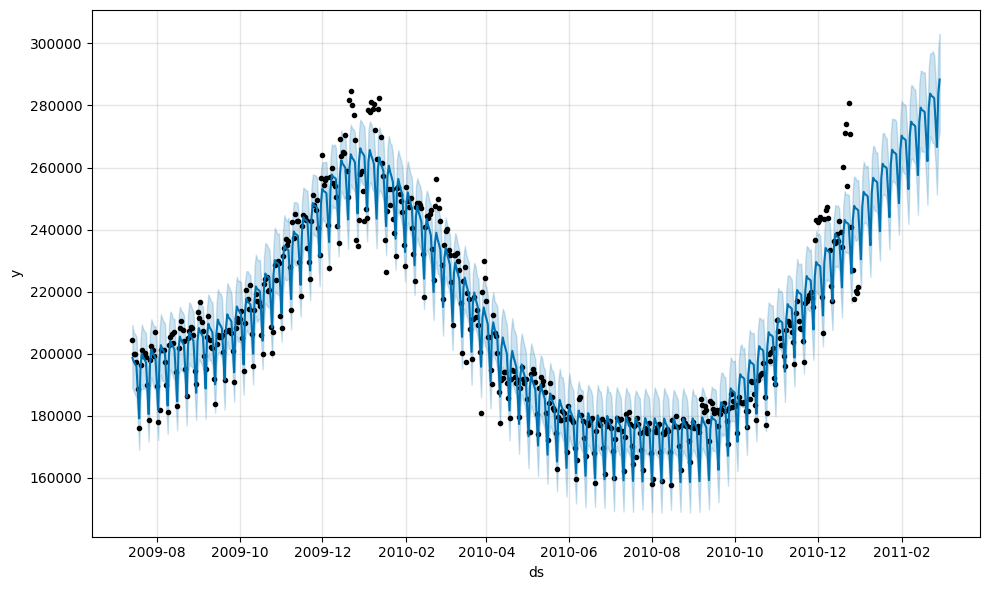

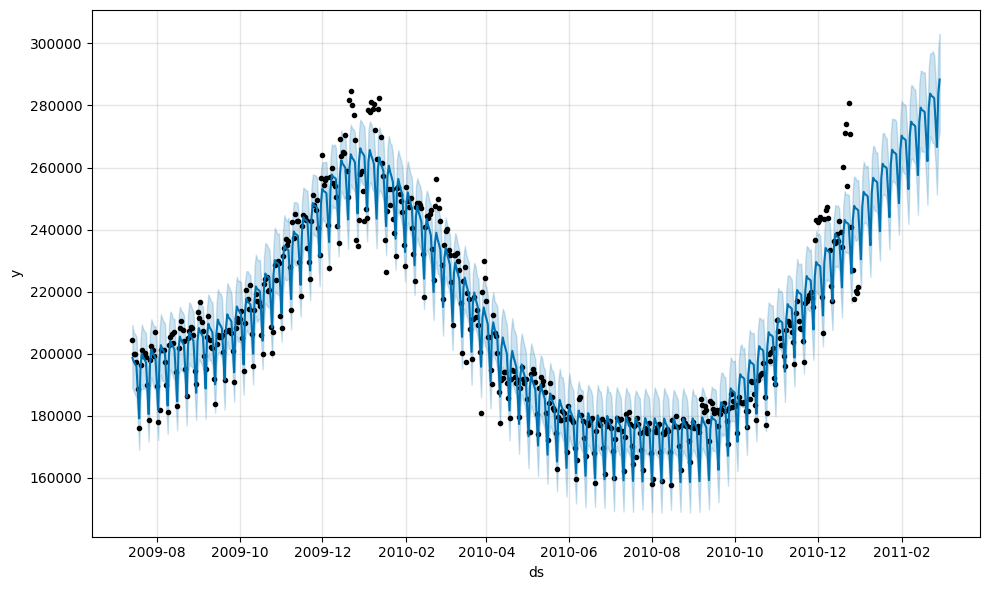

In [ ]:
from prophet import Prophet

model = Prophet()
model.fit(df_daily)

future = model.make_future_dataframe(periods=60)
forecast = model.predict(future)

model.plot(forecast)

In [ ]:
# Creating a future dataframe for 60 days ahead
future = model.make_future_dataframe(periods=60)

# Making predictions
forecast = model.predict(future)


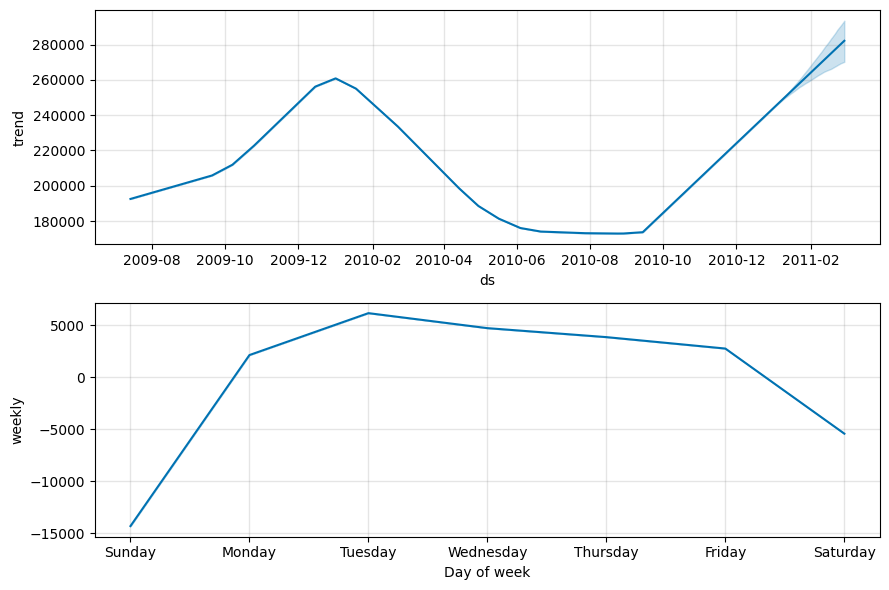

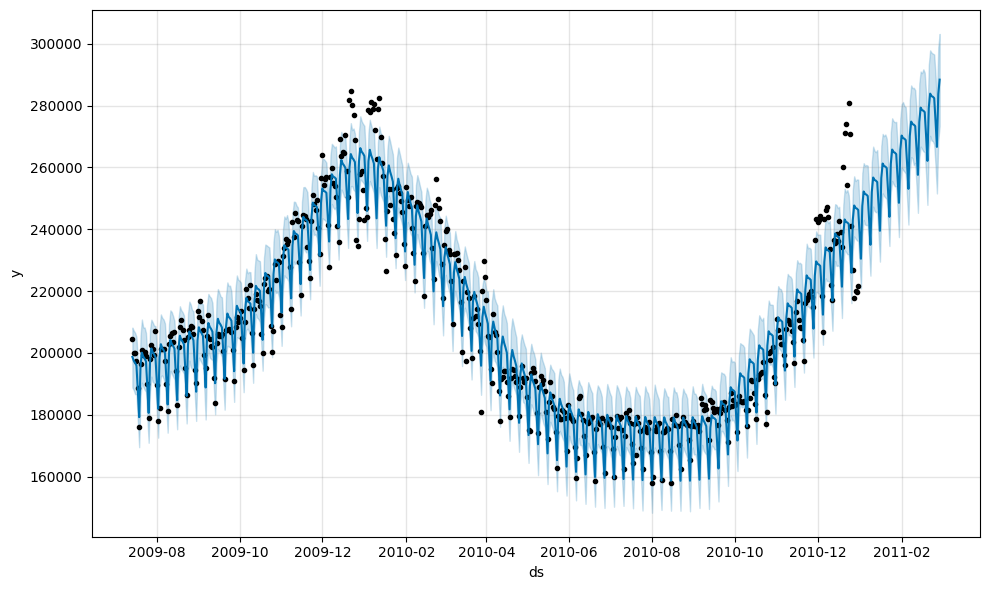

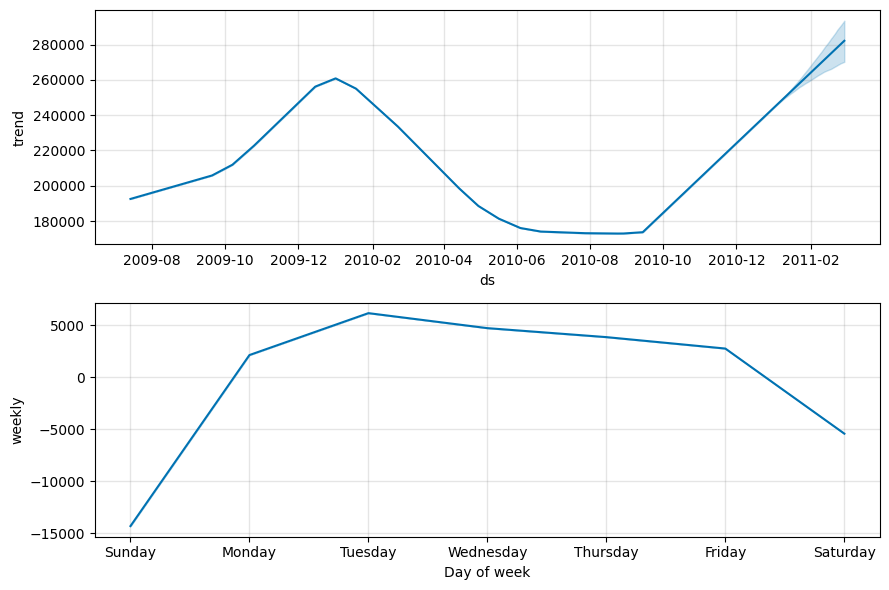

In [ ]:
# Ploting the forecast (including past and future)
model.plot(forecast)

# Ploting the components (trend, seasonality, holidays if any added)
model.plot_components(forecast)


In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Forecasting accuracy check
actual = df_daily['y'].values[-60:]  # Actual consumption in last 60 days (tail of data)
predicted = forecast['yhat'].values[-60:]

# Calculating RMSE (Root Mean Squared Error)
rmse = np.sqrt(mean_squared_error(actual, predicted))
print(f"Forecast RMSE: {rmse:.3f} kWh")


Forecast RMSE: 41014.955 kWh


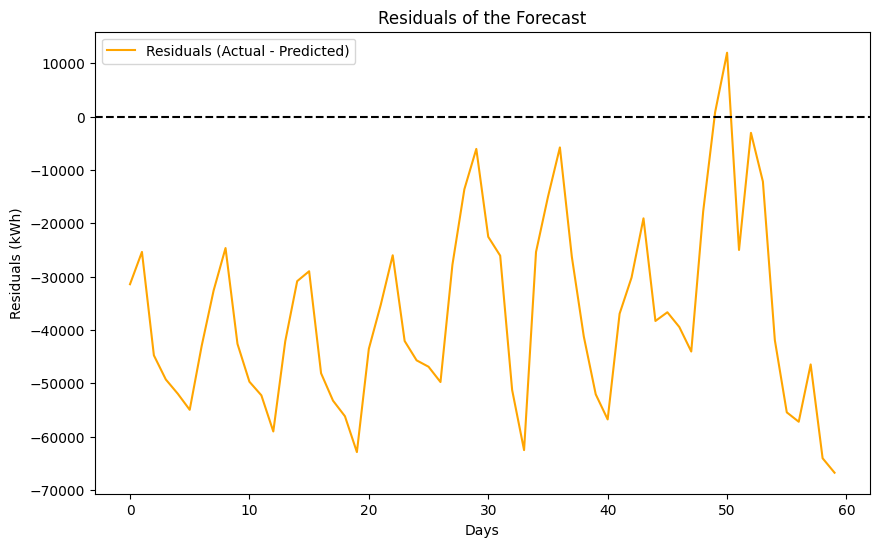

In [ ]:
import matplotlib.pyplot as plt

# Calculating residuals (error between actual and forecasted values)
residuals = actual - predicted

# Ploting residuals (helps evaluate model fit)
plt.figure(figsize=(10,6))
plt.plot(residuals, label='Residuals (Actual - Predicted)', color='orange')
plt.axhline(y=0, color='black', linestyle='--')
plt.title('Residuals of the Forecast')
plt.xlabel('Days')
plt.ylabel('Residuals (kWh)')
plt.legend()
plt.show()


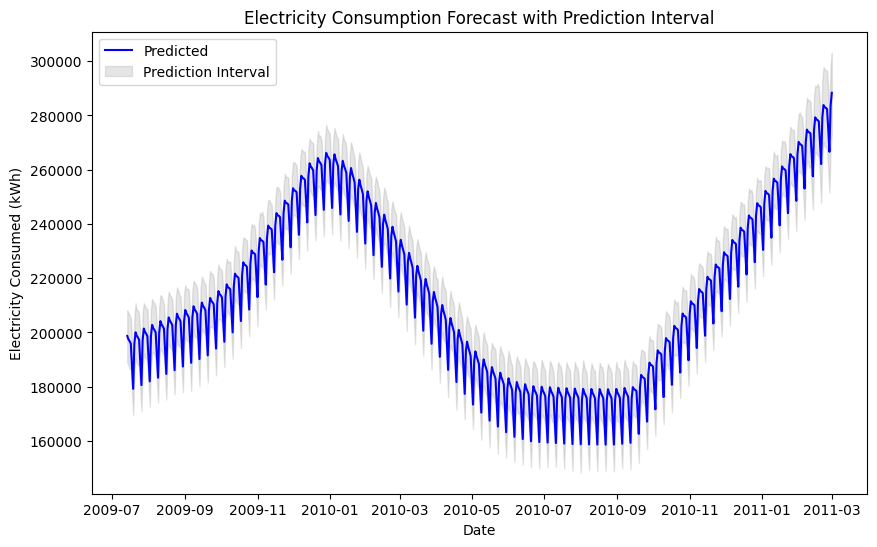

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(forecast['ds'], forecast['yhat'], label='Predicted', color='blue')
plt.fill_between(forecast['ds'], forecast['yhat_lower'], forecast['yhat_upper'], color='gray', alpha=0.2, label="Prediction Interval")
plt.title("Electricity Consumption Forecast with Prediction Interval")
plt.xlabel("Date")
plt.ylabel("Electricity Consumed (kWh)")
plt.legend()
plt.show()

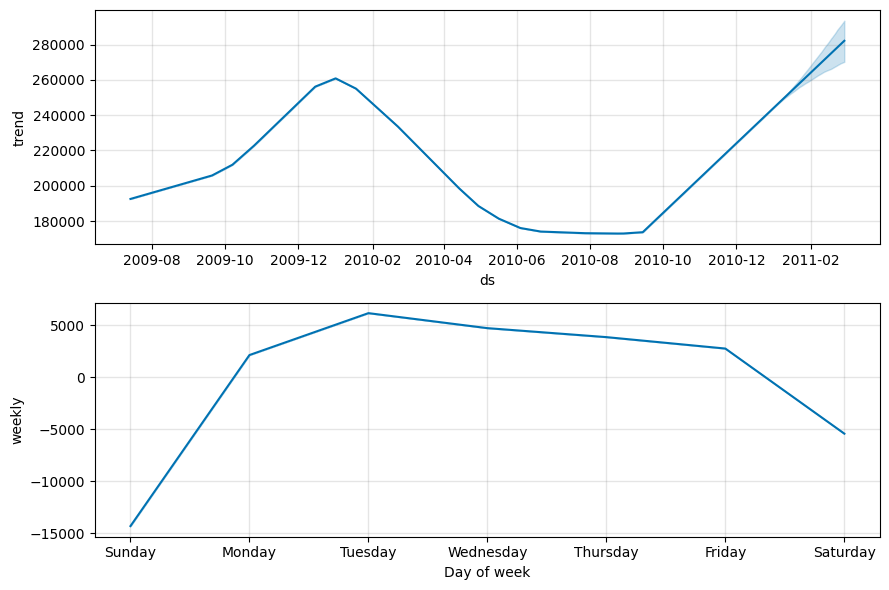

In [ ]:
# Ploting the components (trend, weekly, yearly seasonality)
model.plot_components(forecast)
plt.show()

**Deep Learning Model: LSTM**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df_daily['y'].values.reshape(-1, 1))

# Creating time series samples
def create_dataset(data, time_steps=1):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i:(i + time_steps), 0])
        y.append(data[i + time_steps, 0])
    return np.array(X), np.array(y)

# Splitining into train/test (80/20)
train_size = int(len(scaled_data) * 0.8)
train, test = scaled_data[:train_size], scaled_data[train_size:]

# Create sequences (using 7 days as lookback)
time_steps = 7
X_train, y_train = create_dataset(train, time_steps)
X_test, y_test = create_dataset(test, time_steps)

# Reshaping for LSTM [samples, time steps, features]
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

In [ ]:
# Building LSTM model
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(time_steps, 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

# Training with early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=5)
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

# Making predictions
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.1466 - val_loss: 0.0183
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0150 - val_loss: 0.0091
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0134 - val_loss: 0.0025
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0104 - val_loss: 0.0018
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0101 - val_loss: 0.0018
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0085 - val_loss: 0.0018
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0103 - val_loss: 0.0017
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0090 - val_loss: 0.0020
Epoch 9/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0090 - val_loss: 0.0021
Epoch 10/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0102 - val_loss: 0.0017
Epoch 11/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0090 - val_loss: 0.0018
Epoch 12/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0101 -

In [ ]:
# Inverse transform predictions
train_predict = scaler.inverse_transform(train_predict)
y_train = scaler.inverse_transform([y_train])
test_predict = scaler.inverse_transform(test_predict)
y_test = scaler.inverse_transform([y_test])

# Calculating metrics
def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    return mse, rmse, mae

train_mse, train_rmse, train_mae = calculate_metrics(y_train[0], train_predict[:,0])
test_mse, test_rmse, test_mae = calculate_metrics(y_test[0], test_predict[:,0])

print(f"Train MSE: {train_mse:.2f}, RMSE: {train_rmse:.2f}, MAE: {train_mae:.2f}")
print(f"Test MSE: {test_mse:.2f}, RMSE: {test_rmse:.2f}, MAE: {test_mae:.2f}")

Train MSE: 96117560.45, RMSE: 9803.96, MAE: 7612.59
Test MSE: 174194125.75, RMSE: 13198.26, MAE: 9581.94


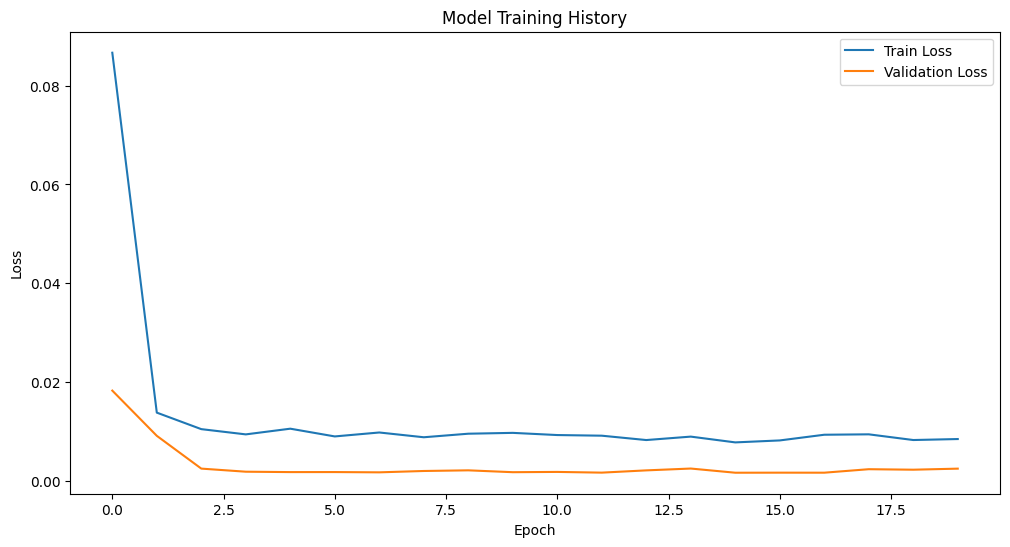

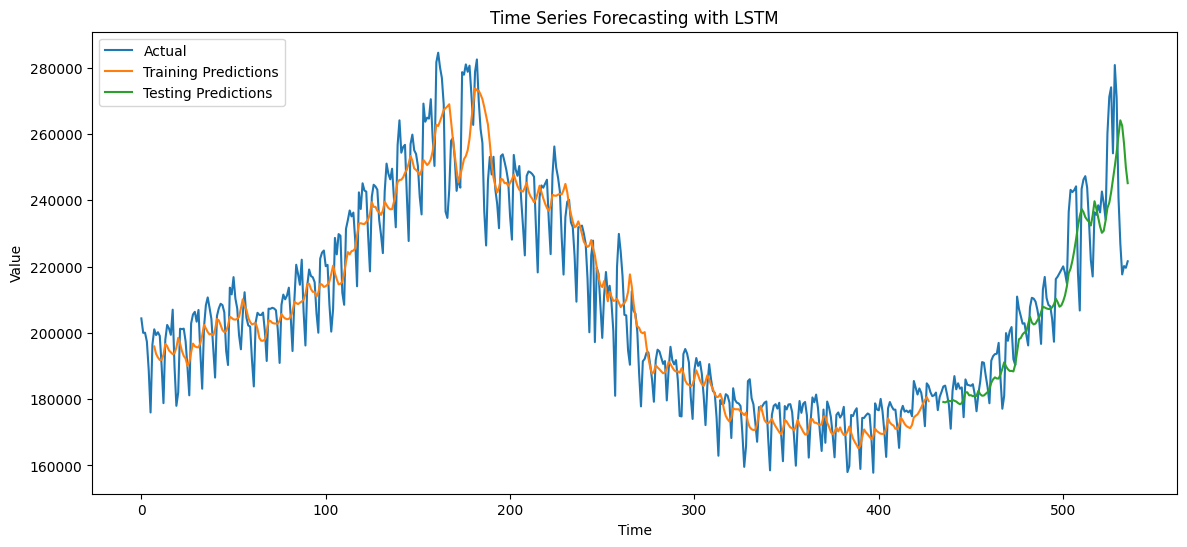

In [ ]:
# Ploting training history
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Training History')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

# Ploting predictions
plt.figure(figsize=(14, 6))

# Shifting train predictions for plotting
train_plot = np.empty_like(scaled_data)
train_plot[:, :] = np.nan
train_plot[time_steps:len(train_predict)+time_steps, :] = train_predict

# Shifting test predictions for plotting
test_plot = np.empty_like(scaled_data)
test_plot[:, :] = np.nan
test_plot[len(train_predict)+(time_steps*2):len(scaled_data), :] = test_predict

# Ploting baseline and predictions
plt.plot(scaler.inverse_transform(scaled_data), label='Actual')
plt.plot(train_plot, label='Training Predictions')
plt.plot(test_plot, label='Testing Predictions')
plt.title('Time Series Forecasting with LSTM')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

**Smart meters Residential pre  -trial survey data Analysis**

C:\Users\Abhi\AppData\Local\Temp\ipykernel_13080\2682937841.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels, y=internet_counts.values, palette='Blues_d')


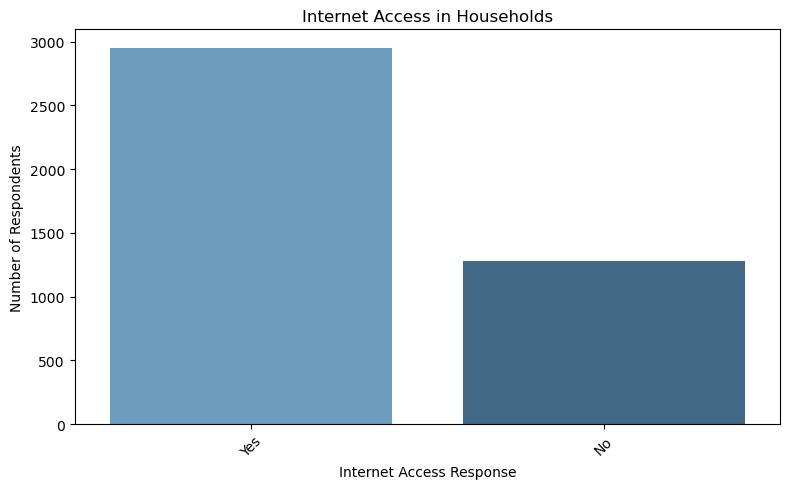

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your Excel file
file_path = r"C:\Users\Abhi\Desktop\Smart meters Residential pre-trial survey data.xlsx"

df = pd.read_excel(file_path)

# Replace long column name with a simpler alias
df.rename(columns={'Question 405: Do you have internet access in your home?': 'Internet Access'}, inplace=True)

# Drop NA and count value counts
internet_counts = df['Internet Access'].dropna().value_counts()


# Create a mapping for labels
label_mapping = {1: 'Yes', 2: 'No'}
# Apply mapping to the index for display
labels = [label_mapping.get(i, str(i)) for i in internet_counts.index]

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(x=labels, y=internet_counts.values, palette='Blues_d')
plt.title('Internet Access in Households')
plt.xlabel('Internet Access Response')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\Abhi\AppData\Local\Temp\ipykernel_13080\2324860936.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels, y=renewable_counts.values, palette='Greens')


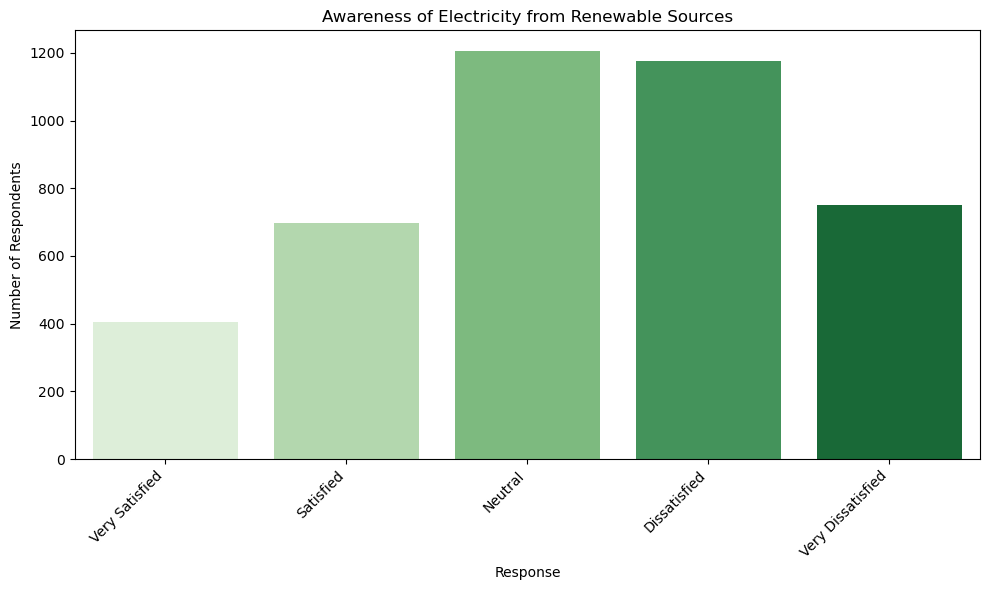

In [ ]:
# Rename for simplicity
df.rename(columns={'Question 55114: The percentage of electricity being generated from renewable sources': 'Renewable Percentage Awareness'}, inplace=True)

# Drop NA and count responses
renewable_counts = df['Renewable Percentage Awareness'].dropna().value_counts().sort_index()


# Create a mapping for responses
response_mapping = {
    1: 'Very Satisfied',
    2: 'Satisfied',
    3: 'Neutral',
    4: 'Dissatisfied',
    5: 'Very Dissatisfied'
}

# Map the index to labels
labels = [response_mapping.get(i, str(i)) for i in renewable_counts.index]

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x=labels, y=renewable_counts.values, palette='Greens')
plt.title('Awareness of Electricity from Renewable Sources')
plt.xlabel('Response')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Smart meters Residential post-trial survey data Analysis**

C:\Users\Abhi\AppData\Local\Temp\ipykernel_13080\3558318309.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels_env, y=env_counts.values, palette='YlGn')


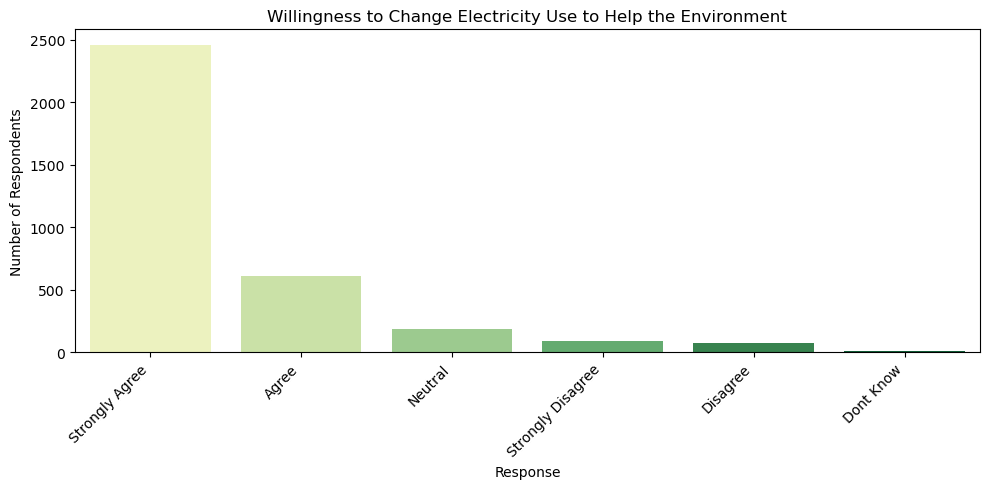

C:\Users\Abhi\AppData\Local\Temp\ipykernel_13080\3558318309.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels_activities, y=activities_counts.values, palette='YlOrBr')


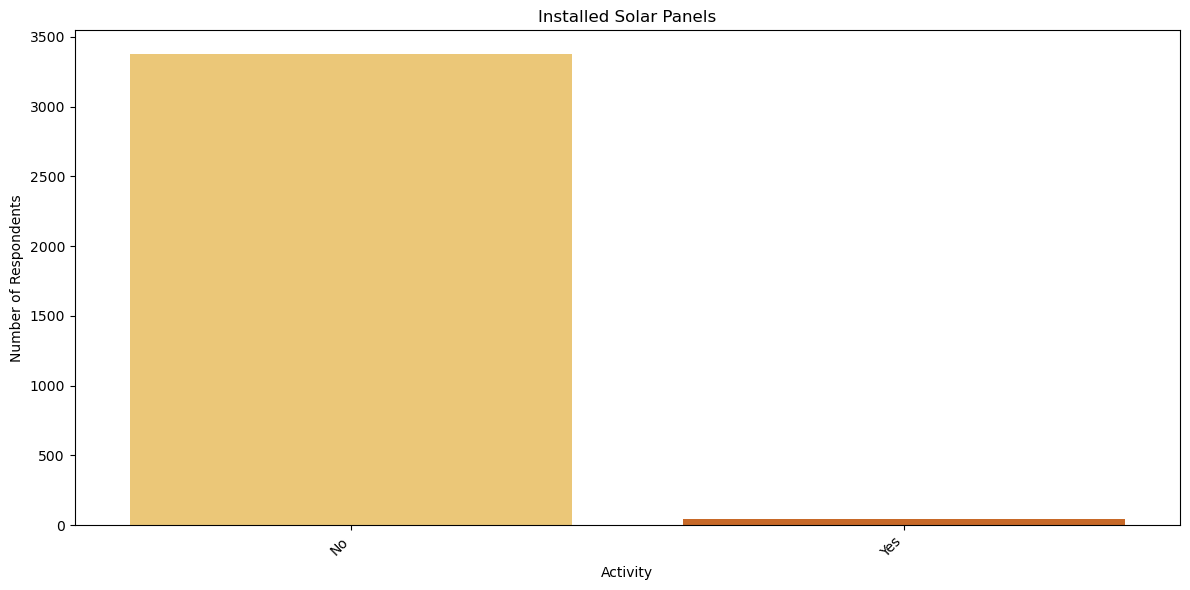

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Excel file
file_path = r"C:\Users\Abhi\Desktop\Smart meters Residential post-trial survey data.xlsx"
df = pd.read_excel(file_path)

# Rename columns for convenience
df.rename(columns={
    'Question 43122: I am interested in changing the way I use electricity if it helps the environment': 'Interest in Change for Environment',
    'Question 4906: Over the last twelve months have you done any of the: Added solar panels': 'Installed Solar Panels'
}, inplace=True)

# Define response mappings for the first question
interest_response_mapping = {
    1: 'Strongly Agree',
    2: 'Agree',
    3: 'Neutral',
    4: 'Disagree',
    5: 'Strongly Disagree',
    6: 'Dont Know'
}

# Define response mappings for the second question
activities_response_mapping = {
    0: 'No',
    1: 'Yes',
}

# Plot 1: Interest in changing electricity use
plt.figure(figsize=(10, 5))
env_counts = df['Interest in Change for Environment'].dropna().value_counts()
labels_env = [interest_response_mapping.get(i, str(i)) for i in env_counts.index]
sns.barplot(x=labels_env, y=env_counts.values, palette='YlGn')
plt.title('Willingness to Change Electricity Use to Help the Environment')
plt.ylabel('Number of Respondents')
plt.xlabel('Response')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plot 2: Activities done over last 12 months
plt.figure(figsize=(12, 6))
activities_counts = df['Installed Solar Panels'].dropna().value_counts()
labels_activities = [activities_response_mapping.get(i, str(i)) for i in activities_counts.index]
sns.barplot(x=labels_activities, y=activities_counts.values, palette='YlOrBr')
plt.title('Installed Solar Panels')
plt.ylabel('Number of Respondents')
plt.xlabel('Activity')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Model Comparison**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import timedelta
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.svm import SVR
from statsmodels.tsa.arima.model import ARIMA
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from prophet import Prophet

# Reloading and preparing data
df = pd.read_parquet("daily_aggregated_data.parquet")
df = df.reset_index()
df_daily = df.groupby(df.columns[0])[df.columns[2]].sum().reset_index()
df_daily.columns = ['ds', 'y']


In [3]:
# Function to calculating NRMSE (Normalized Root Mean Square Error)
def calculate_nrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / (np.max(y_true) - np.min(y_true))

# Function to evaluating model performance
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    nrmse = calculate_nrmse(y_true, y_pred)

    print(f"{model_name} Metrics:")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE: {mae:.2f}")
    print(f"NRMSE: {nrmse:.4f}")

    return rmse, mae, nrmse



In [4]:
# Spliting data for training and testing
train_size = int(len(df_daily) * 0.8)
train_data = df_daily.iloc[:train_size]
test_data = df_daily.iloc[train_size:]

print(f"Training data size: {len(train_data)}")
print(f"Testing data size: {len(test_data)}")

# Converting datetime to numerical feature for non-Prophet models
df_daily['date_num'] = (pd.to_datetime(df_daily['ds']) - pd.to_datetime(df_daily['ds'].min())).dt.days

# Making sure the date_num column is also in the train and test datasets
train_data['date_num'] = (pd.to_datetime(train_data['ds']) - pd.to_datetime(df_daily['ds'].min())).dt.days
test_data['date_num'] = (pd.to_datetime(test_data['ds']) - pd.to_datetime(df_daily['ds'].min())).dt.days

# Creating feature matrices
X_train = np.array(train_data['date_num']).reshape(-1, 1)
y_train = train_data['y'].values
X_test = np.array(test_data['date_num']).reshape(-1, 1)
y_test = test_data['y'].values

# Scaling the data for SVR and RNN models
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()


Training data size: 428
Testing data size: 108


<ipython-input-4-c8db9cb9ebdd>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data['date_num'] = (pd.to_datetime(train_data['ds']) - pd.to_datetime(df_daily['ds'].min())).dt.days
<ipython-input-4-c8db9cb9ebdd>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_data['date_num'] = (pd.to_datetime(test_data['ds']) - pd.to_datetime(df_daily['ds'].min())).dt.days


**Prophet Model**

In [5]:
# 1. Prophet Model
model_prophet = Prophet()
model_prophet.fit(train_data)

# Making future dataframe for the test period and beyond
future_prophet = model_prophet.make_future_dataframe(periods=len(test_data) + 60)
forecast_prophet = model_prophet.predict(future_prophet)

# Extracting predictions for the test period
prophet_pred = forecast_prophet.iloc[train_size:train_size + len(test_data)]['yhat'].values

# Evaluating Prophet model
prophet_metrics = evaluate_model(y_test, prophet_pred, "Prophet")


INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmp_jy_8bv5/ajchev_k.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp_jy_8bv5/kl4d4d7l.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.11/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=41194', 'data', 'file=/tmp/tmp_jy_8bv5/ajchev_k.json', 'init=/tmp/tmp_jy_8bv5/kl4d4d7l.json', 'output', 'file=/tmp/tmp_jy_8bv5/prophet_modelu5xy0tpb/prophet_model-20250507073346.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
07:33:46 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
07:33:46 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Prophet Metrics:
RMSE: 39616.96
MAE: 31219.84
NRMSE: 0.3610


**SVR Model**

In [6]:
# SVR Model
# Training SVR model
svr_model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svr_model.fit(X_train_scaled, y_train_scaled)

# Predicting and inverse transform
svr_pred_scaled = svr_model.predict(X_test_scaled)
svr_pred = scaler_y.inverse_transform(svr_pred_scaled.reshape(-1, 1)).flatten()

# Evaluating SVR model
svr_metrics = evaluate_model(y_test, svr_pred, "SVR")


SVR Metrics:
RMSE: 106681.52
MAE: 97055.74
NRMSE: 0.9721


**RNN(LSTM) Model**

In [7]:
# RNN (LSTM) Model
# Function to create sequences for LSTM
def create_sequences(X, y, time_steps=1):
    Xs, ys = [], []
    for i in range(len(X) - time_steps):
        Xs.append(X[i:(i + time_steps)])
        ys.append(y[i + time_steps])
    return np.array(Xs), np.array(ys)

# Preparing data for LSTM (time steps = 7 for weekly patterns)
time_steps = 7
if len(X_train_scaled) > time_steps:
    # Creating sequences for training
    X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train_scaled, time_steps)

    # Building LSTM model
    lstm_model = Sequential([
        LSTM(50, activation='relu', input_shape=(time_steps, 1), return_sequences=True),
        Dropout(0.2),
        LSTM(50, activation='relu'),
        Dropout(0.2),
        Dense(1)
    ])

    lstm_model.compile(optimizer='adam', loss='mse')

    # Reshaping for LSTM [samples, time steps, features]
    X_train_seq = X_train_seq.reshape(X_train_seq.shape[0], X_train_seq.shape[1], 1)

    # Training model
    lstm_model.fit(X_train_seq, y_train_seq, epochs=50, batch_size=32, verbose=0)

    # Preparing test data sequences
    test_seq = []
    # Use the last 'time_steps' points from training data to predict the first test point
    last_train = X_train_scaled[-time_steps:].flatten()
    current_seq = last_train.tolist()

    # Making predictions one by one
    lstm_pred_scaled = []

    for i in range(len(X_test_scaled)):
        # Reshaping current sequence for prediction
        current_seq_array = np.array(current_seq[-time_steps:])
        current_seq_array = current_seq_array.reshape(1, time_steps, 1)

        # Predicting next value
        next_pred = lstm_model.predict(current_seq_array, verbose=0)[0][0]
        lstm_pred_scaled.append(next_pred)

        # Updating sequence with the new prediction (for forecasting next point)
        current_seq.append(X_test_scaled[i][0])

    # Transforming predictions back to original scale
    lstm_pred = scaler_y.inverse_transform(np.array(lstm_pred_scaled).reshape(-1, 1)).flatten()

    # Evaluating LSTM model
    lstm_metrics = evaluate_model(y_test, lstm_pred, "LSTM (RNN)")
else:
    print("Not enough data points for LSTM sequences")
    lstm_metrics = None



/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM (RNN) Metrics:
RMSE: 44181.73
MAE: 35847.24
NRMSE: 0.4026


**ARIMA Model**

In [8]:
# ARIMA Model
# Creating time series for ARIMA
ts_train = pd.Series(train_data['y'].values, index=pd.to_datetime(train_data['ds']))

# Fiting ARIMA model (p,d,q) parameters
# p: order of AR term
# d: differencing
# q: order of MA term
try:
    arima_model = ARIMA(ts_train, order=(5, 1, 0))
    arima_fit = arima_model.fit()

    # Forecast
    arima_pred = arima_fit.forecast(steps=len(test_data))

    # Evaluating ARIMA model
    arima_metrics = evaluate_model(y_test, arima_pred, "ARIMA")
except Exception as e:
    print(f"ARIMA model error: {e}")
    arima_metrics = None


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


ARIMA Metrics:
RMSE: 36795.48
MAE: 27288.84
NRMSE: 0.3353


**Model compairison**

In [9]:
# Comparing all models
# Creating comparison table
models = ['Prophet', 'SVR', 'LSTM (RNN)', 'ARIMA']
metrics = [prophet_metrics, svr_metrics, lstm_metrics, arima_metrics]

metrics_df = pd.DataFrame(columns=['Model', 'RMSE', 'MAE', 'NRMSE'])

for i, model in enumerate(models):
    if metrics[i] is not None:
        new_row = pd.DataFrame({
            'Model': [model],
            'RMSE': [metrics[i][0]],
            'MAE': [metrics[i][1]],
            'NRMSE': [metrics[i][2]]
        })
    metrics_df = pd.concat([metrics_df, new_row], ignore_index=True)

print("\nModel Comparison:")
print(metrics_df.sort_values('RMSE'))



Model Comparison:
        Model           RMSE           MAE     NRMSE
3       ARIMA   36795.481770  27288.837916  0.335294
0     Prophet   39616.963016  31219.837019  0.361005
2  LSTM (RNN)   44181.733782  35847.238281  0.402601
1         SVR  106681.521811  97055.738529  0.972123


<ipython-input-9-797753dd640b>:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  metrics_df = pd.concat([metrics_df, new_row], ignore_index=True)


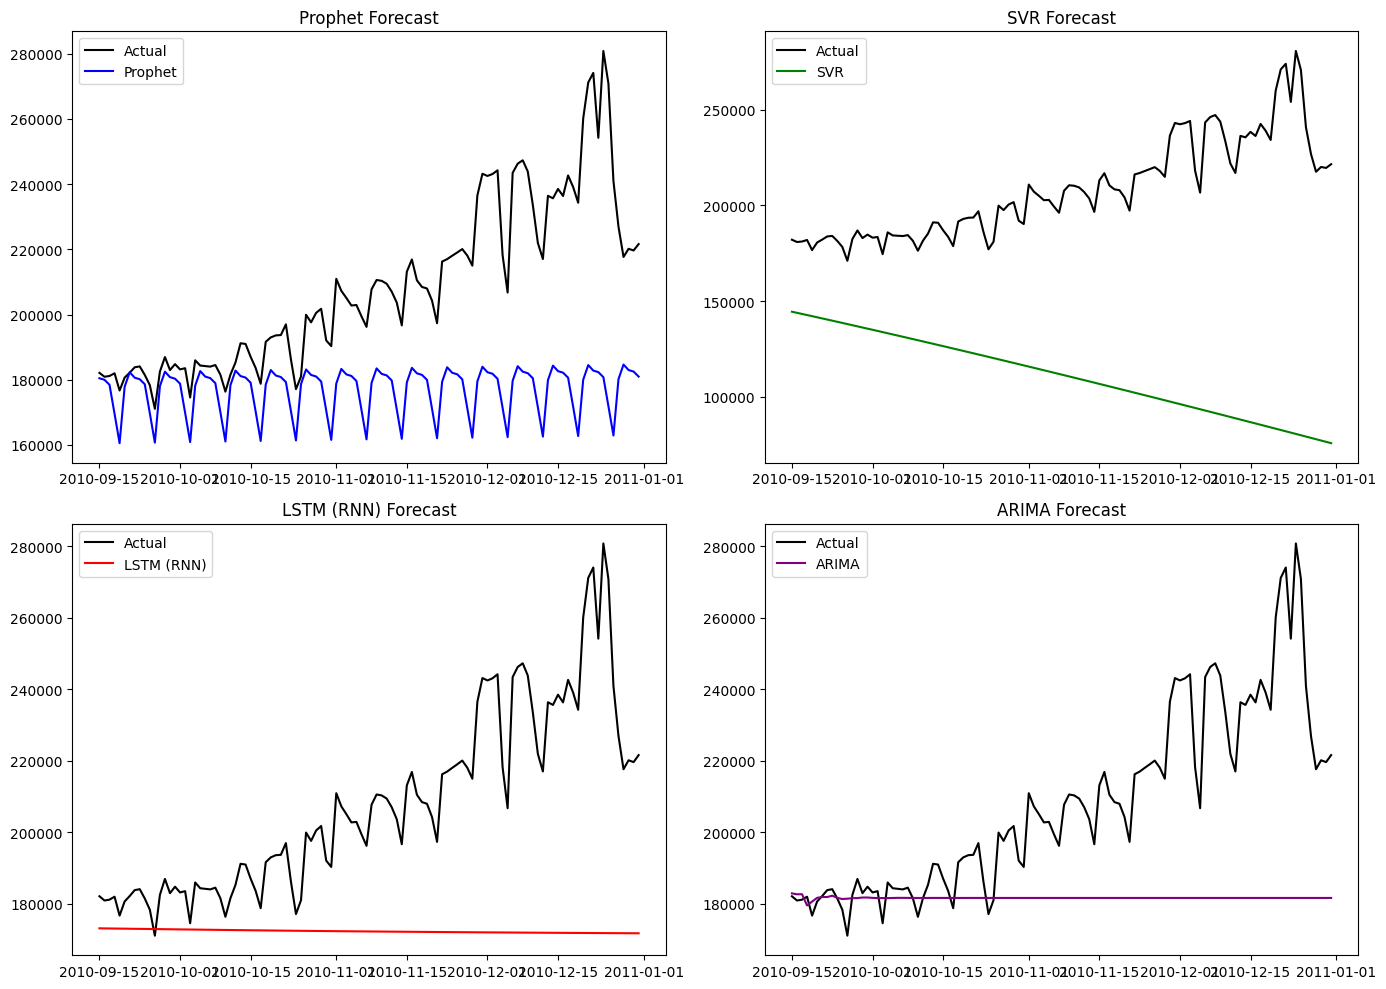

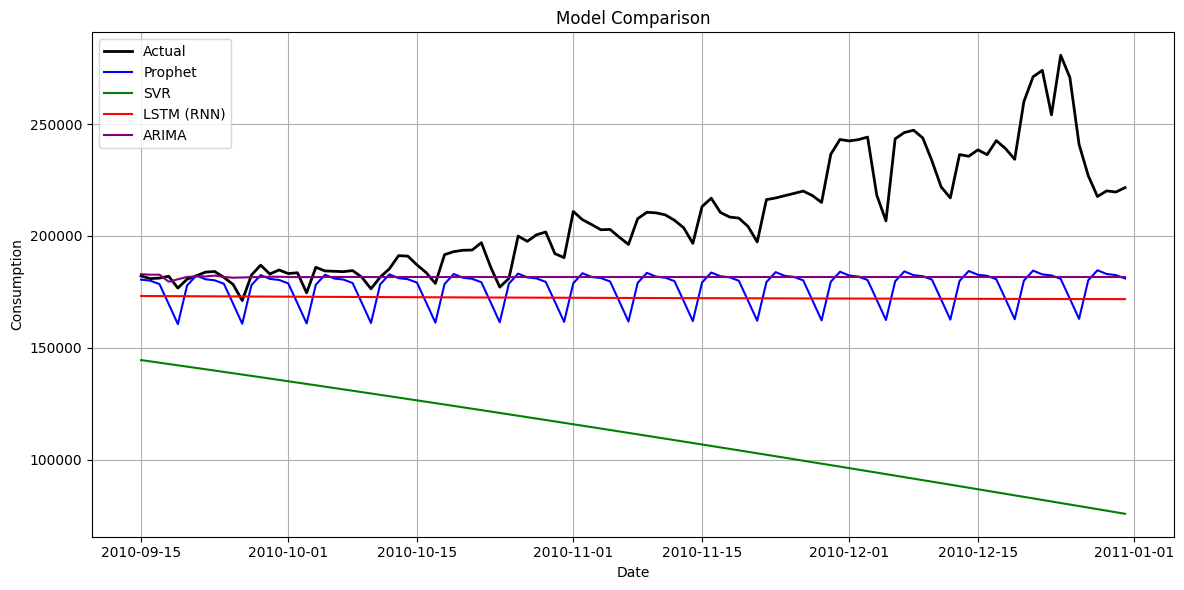

In [10]:



# Ploting Results
#---------------------------------
plt.figure(figsize=(14, 10))

# Actual values
plt.subplot(2, 2, 1)
plt.plot(test_data['ds'], y_test, label='Actual', color='black')
plt.plot(test_data['ds'], prophet_pred, label='Prophet', color='blue')
plt.title('Prophet Forecast')
plt.legend()

# SVR
plt.subplot(2, 2, 2)
plt.plot(test_data['ds'], y_test, label='Actual', color='black')
plt.plot(test_data['ds'], svr_pred, label='SVR', color='green')
plt.title('SVR Forecast')
plt.legend()

# LSTM
plt.subplot(2, 2, 3)
if lstm_metrics is not None:
    plt.plot(test_data['ds'], y_test, label='Actual', color='black')
    plt.plot(test_data['ds'], lstm_pred, label='LSTM (RNN)', color='red')
    plt.title('LSTM (RNN) Forecast')
    plt.legend()
else:
    plt.text(0.5, 0.5, 'Insufficient data for LSTM', ha='center', va='center')
    plt.title('LSTM (RNN) - Not Available')

# ARIMA
plt.subplot(2, 2, 4)
if arima_metrics is not None:
    plt.plot(test_data['ds'], y_test, label='Actual', color='black')
    plt.plot(test_data['ds'], arima_pred, label='ARIMA', color='purple')
    plt.title('ARIMA Forecast')
    plt.legend()
else:
    plt.text(0.5, 0.5, 'ARIMA model error', ha='center', va='center')
    plt.title('ARIMA - Not Available')

plt.tight_layout()
plt.savefig('model_comparison.png')
plt.show()

# Create a combined plot with all models
plt.figure(figsize=(12, 6))
plt.plot(test_data['ds'], y_test, label='Actual', color='black', linewidth=2)
plt.plot(test_data['ds'], prophet_pred, label='Prophet', color='blue')
plt.plot(test_data['ds'], svr_pred, label='SVR', color='green')
if lstm_metrics is not None:
    plt.plot(test_data['ds'], lstm_pred, label='LSTM (RNN)', color='red')
if arima_metrics is not None:
    plt.plot(test_data['ds'], arima_pred, label='ARIMA', color='purple')

plt.title('Model Comparison')
plt.xlabel('Date')
plt.ylabel('Consumption')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('all_models_comparison.png')
plt.show()
